# Terminal rendering with meshio++ (Octave/MATLAB)

Octave/MATLAB counterpart of [`../r/04_terminal_rendering.ipynb`](../r/04_terminal_rendering.ipynb) and
[`../python/31_terminal_rendering.ipynb`](../python/31_terminal_rendering.ipynb): meshio++'s own **software
rasterizer** draws a mesh with no display, GPU or plotting package, called through the Octave/MATLAB binding
(`mio.render`, `mio.render_png`, `mio.render_text`, `mio.write_snapshot`). It reaches **every** option of the
rasterizer through the C API, so the pictures below are coloured by data, with contour lines, arrows,
streamlines and a cut-away. See [`doc/tui.md`](../../doc/tui.md) and [`doc/octave.md`](../../doc/octave.md).

`mio.render` returns a frame struct whose `rgba` field is an `H x W x 4` `uint8` array with row 1 at the top,
so `image(f.rgba(:, :, 1:3)); axis image off` shows it upright. [`mio_frame_image.m`](mio_frame_image.m) does
exactly that in a figure the size of the frame, and the octave kernel shows the figure inline.

In [1]:
warning('off', 'Octave:shadowed-function');
addpath(fullfile(pwd, '..', '..', 'bindings', 'octave', 'meshioplusplus', 'inst'));
mio_notebook

mesh = mio.read('example.vtu');
fprintf('points: %d, blocks: %s\n', mio.num_points(mesh), strjoin(mio.cell_block_types(mesh)', ', '));

meshio++ 18.2.0 (Octave/MATLAB binding)


points: 52282, blocks: triangle, tetra


## Some fields to draw

The bracket carries no solution, so make some from its geometry: a scalar `h`, a displacement `disp` and a
rotation velocity `vel` about the part's vertical axis. A vector point array is a `num_points x 3` matrix,
one point per row (R's is `3 x N`).

In [2]:
P = mio.points(mesh);
mid = mean(P, 1);
lo = min(P, [], 1);
hi = max(P, [], 1);
n = size(P, 1);
mio.add_point_data(mesh, 'h', P(:, 1) + 0.5 * P(:, 2));
mio.add_point_data(mesh, 'disp', [zeros(n, 2), 0.15 * (P(:, 1) - lo(1)) / (hi(1) - lo(1))]);
mio.add_point_data(mesh, 'vel', [-(P(:, 2) - mid(2)), P(:, 1) - mid(1), zeros(n, 1)]);
fprintf('point data: %s\n', strjoin(mio.point_data_names(mesh)', ', '));

point data: disp, h, vel


## A frame

`mio_frame_image` takes the options of `mio.render` as name/value pairs: a named `'view'`, `'edges', 'feature'`
for the sharp edges, `'shading', 'smooth'`. A volume is drawn through its boundary skin.

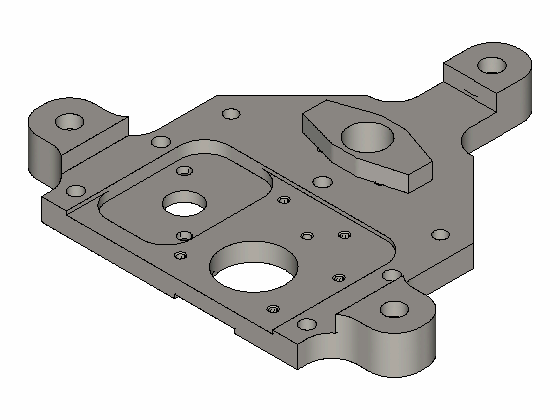

In [3]:
mio_frame_image(mesh, 'edges', 'feature', 'shading', 'smooth', 'background', mio.rgba(255, 255, 255));

## Colouring by data

`'color_by'` takes point data first, then cell data. `mio.render` returns a frame struct with the pixels
(`rgba`), the 1-based cell id of every pixel (`cell_ids`, `0` for the background), the mapped `range` and the
`notes` a terminal rendering prints under its picture.

range: -4.18187 -0.00318038


h: -4.18187 .. -0.00318038 (plasma)
ticks: -4, -3, -2, -1


frame: 420 x 560 x 4 uint8, 22994 cells visible


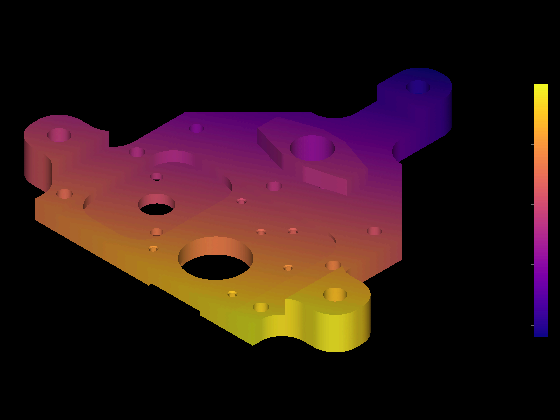

In [4]:
f = mio.render(mesh, 'width', 560, 'height', 420, 'color_by', 'h', 'colorbar', true, 'cmap', 'plasma');
fprintf('range: %g %g\n', f.range);
fprintf('%s\n', f.notes{:});
fprintf('frame: %d x %d x %d %s, %d cells visible\n', size(f.rgba), class(f.rgba), ...
    numel(unique(f.cell_ids(f.cell_ids > 0))));
mio_frame_image(mesh, 'color_by', 'h', 'colorbar', true, 'cmap', 'plasma', 'shading', 'smooth');

`cell_ids` is a pick buffer: the same `H x W` layout as the picture, so it can be shown as an image too.
Here every visible cell gets its own grey level -- the skin's triangles, as the rasterizer saw them.

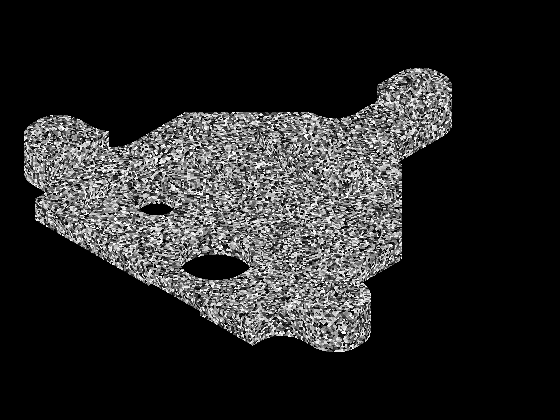

In [5]:
ids = f.cell_ids;
figure('position', [100 100 560 420]);
axes('position', [0 0 1 1]);
imagesc(mod(ids * 7919, 251) .* (ids > 0));
colormap(gray(256));
axis image off

## Field options

Contour lines of a point array, arrows for a vector array, and a warp by a displacement that also draws the
undeformed outline.

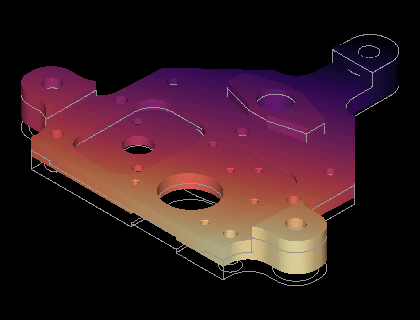

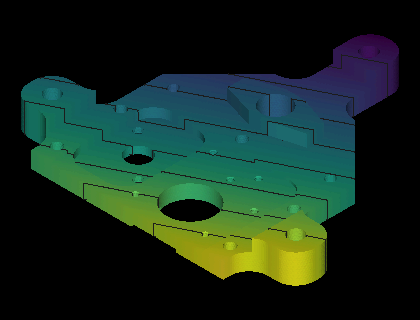

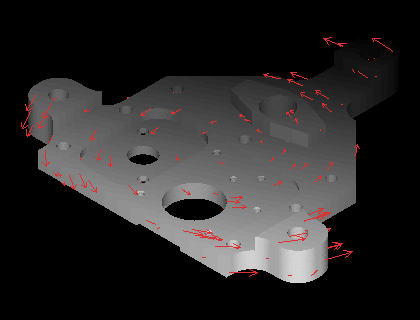

In [6]:
mio_frame_image(mesh, 'color_by', 'h', 'isolines', 8, 'cmap', 'viridis', 'width', 420, 'height', 320);
mio_frame_image(mesh, 'color_by', 'h', 'vectors', 'vel', 'vector_count', 300, 'cmap', 'grey', 'width', 420, 'height', 320);
mio_frame_image(mesh, 'color_by', 'h', 'warp', 'disp', 'warp_outline', true, 'cmap', 'magma', 'width', 420, 'height', 320);

## Streamlines

Added in v16.37.0. `'streamlines', 'vel'` follows a vector point array over the mesh's own cells: on the skin
(a surface) the lines stay on it, and in the volume they run inside it, so a `'cutaway'` shows them.
`'cutaway'` is a point and the normal of the side kept; `-z` through the middle keeps the lower half and tints
the inside.

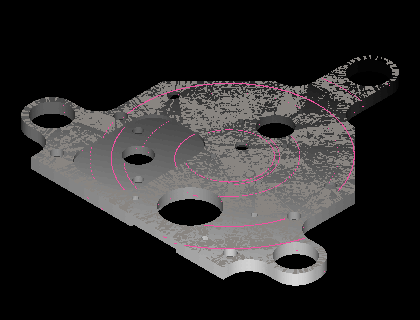

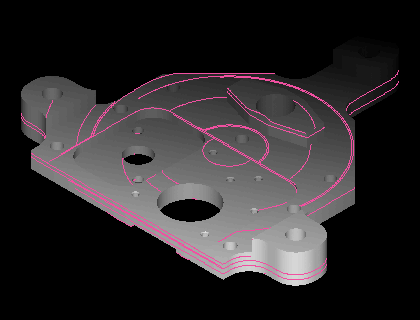

In [7]:
skin = mio.extract_skin(mesh, 'linearize', true);
mio_frame_image(skin, 'color_by', 'h', 'cmap', 'grey', 'streamlines', 'vel', 'stream_seeds', 60, ...
    'stream_length', 0.4, 'shading', 'smooth', 'width', 420, 'height', 320);
mio_frame_image(mesh, 'color_by', 'h', 'cmap', 'grey', 'streamlines', 'vel', 'stream_seeds', 120, ...
    'stream_length', 0.4, 'shading', 'smooth', 'cutaway', [mid, 0, 0, -1], ...
    'width', 420, 'height', 320);

## The terminal form

`mio.render_text` returns what a terminal prints, as a char row: block glyphs with colour escapes, or glyphs
only with `'color_depth', 'mono'`.

In [8]:
disp(mio.render_text(mesh, 'cols', 64, 'rows', 18, 'encoding', 'braille', 'color_depth', 'mono', 'edges', 'feature'));

⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀
⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⢀⣤⣶⢟⣛⡻⣶⣤⠀⠀⠀⠀⠀⠀⠀⠀
⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⢶⣭⡛⠬⣭⣥⠿⡋⠀⠀⠀⠀⠀⠀⠀⠀
⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⣀⣀⣀⡀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⣀⣤⣤⣤⣤⣤⣤⣤⣤⣤⡤⢀⠤⠤⣤⣀⣀⠀⠀⣀⣠⣴⣾⣷⣦⣉⠓⡎⣴⣮⡇⠀⠀⠀⠀⠀⠀⠀⠀
⠀⠀⠀⠀⠀⠀⠀⠀⣶⣿⠫⣭⡍⢻⣷⡦⢄⠀⠀⠀⠀⢀⣠⣴⣿⣿⣅⣒⣽⣿⣿⣿⣿⣿⠑⢾⣿⣿⡿⠶⡪⠭⢙⠿⣿⣿⣿⣿⣿⣿⡿⢛⣠⣿⡿⠃⠀⠀⠀⠀⠀⠀⠀⠀
⠀⠀⠀⠀⠀⠀⠀⠀⢈⡛⢷⣶⠾⣛⢥⡶⣛⣤⣤⡄⠬⠹⠟⣛⣛⣛⡻⢿⣿⣿⣿⣿⣿⣿⣄⠀⠙⠏⢰⣿⣿⣿⠇⣱⣎⠻⣿⣿⣿⡏⢸⠿⠛⠁⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀
⠀⠀⠀⠀⠀⠀⠀⠀⢸⣿⠀⣴⠎⣢⣵⣾⣿⣿⠿⢛⡭⢖⠫⢭⣭⣭⣭⡓⠮⣙⠻⣿⣿⣿⣿⣧⣄⠳⣦⣔⣒⠶⢾⣿⣿⡷⠘⣿⣿⣷⡄⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀
⠀⠀⠀⠀⠀⠀⠀⠀⠘⠻⠀⠶⠿⢿⣿⠿⣋⠥⢚⣭⣾⣷⣥⣴⣿⣿⣿⣿⣷⣮⣄⢠⡙⠻⢿⠫⠭⣻⣶⣭⣛⠛⠳⣶⢰⠾⣃⣿⣿⣿⡇⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀
⠀⠀⠀⠀⠀⠀⠀⠀⠀⣐⡺⠮⠍⣈⠀⣪⣵⣾⣿⣿⡏⠖⠒⠒⠎⣿⣿⣿⡿⢛⣥⣎⠉⣷⣦⣌⡛⠿⣿⣿⣿⣿⣿⣶⣶⣾⣿⣿⣿⣿⡇⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀
⠀⠀⠀⠀⠀⠀⠀⠀⠀⠻⢿⣦⣛⠿⣧⣝⡻⢿⣿⣿⣷⣦⣤⣤⡶⠟⣫⣵⣾⣿⣿⣿⣿⣿⣿⣿⣿⣶⣄⡉⠻⢿⣿⣿⣿⣿⣿⠿⣿⣿⡇⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀
⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠈⠛⠿⣦⣍⡻⢶⣬⣛⣛⣃⣀⣤⣶⣿⠿⣛⣛⣛⠛⢛⠿⣿⣀⣼⣿⣧⣤⣿⣷⣦⣈⢻⣿⣿⣧⣭⣼⡿⠃⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀
⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠉⠻⢷⣬⣙⠿⣧⣤⣿⣿⠁⠿⠛⠛⠛⠉⠑⠒⠈⣿⣿⣿⣿⣿⣿⣿⠟⠋⢼⣿⣿⠟⣫⣵⣾⠇⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀
⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠉⠛⠿⣮⣝⡻⢿⣦⣀⠀⠀⠀⠀⠀⣀⣴⣿⣿⣿⡄⠜⣉⣴⠦⣉⣥⡉⠶⡿⠛⠉⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀
⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠈⠙⠲⢬⣛⠿⣿⣿⡟⠛⣿⣿⠿⢛⣡⡶⢟⣩⣴⡟⣫⣭⢻⣷⣆⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀
⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠉⠛⣦⣝⡻⠖⣉⣄⠤⢉⠿⠰⣶⣭⡛⠷⠶⠶⠾⢛⡁⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀
⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀

## Files

`mio.write_snapshot` picks the form from the extension (`.png`, `.txt`, `.ansi`, `.html`, or a `.cast` orbit
for asciinema). `mio.render_png` returns the PNG bytes as a `uint8` column instead of writing a file.

In [9]:
snapdir = tempname();
mkdir(snapdir);
names = {'part.png', 'part.txt', 'part.html', 'part.cast'};
for k = 1:numel(names)
    path = fullfile(snapdir, names{k});
    mio.write_snapshot(path, mesh, 'width', 320, 'height', 240, 'cols', 60, 'rows', 16, ...
        'streamlines', 'vel', 'stream_seeds', 30, 'cast_frames', 6);
    d = dir(path);
    fprintf('%-10s %d bytes\n', names{k}, d.bytes);
end
fid = fopen(fullfile(snapdir, 'part.png'), 'r');
sig = fread(fid, 8, 'uint8=>uint8');
fclose(fid);
fprintf('PNG signature: %d\n', isequal(sig, uint8([137; 80; 78; 71; 13; 10; 26; 10])));
png = mio.render_png(mesh, 'width', 320, 'height', 240);
fprintf('mio.render_png: %d bytes, %s %d x %d\n', numel(png), class(png), size(png));

part.png   307528 bytes


part.txt   1675 bytes


part.html  12449 bytes


part.cast  49157 bytes


PNG signature: 1


mio.render_png: 307528 bytes, uint8 307528 x 1


The snapshot PNG reads back with `imread`, a plain image like any other:

imread: 240 x 320 x 3 uint8


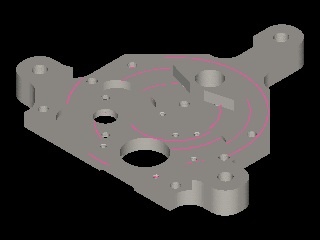

In [10]:
img = imread(fullfile(snapdir, 'part.png'));
fprintf('imread: %d x %d x %d %s\n', size(img), class(img));
figure('position', [100 100 size(img, 2) size(img, 1)]);
axes('position', [0 0 1 1]);
image(img(:, :, 1:3));
axis image off